# 03 — Feature Set Ablation Analysis (F0 → F1 → F2 → F3)

Đánh giá đóng góp biên của các nhóm biến: F0 (Nội sinh), F1 (Khí tượng ngoại sinh), F2 (Biến trễ & Rolling), F3 (Lịch biểu & Mùa vụ) trên các họ Tabular ML Direct, Tweedie và Hurdle.

### Project Guardrails & Execution Baseline:
- **Protocol Căn cứ:** `training_forecasting_evaluation_protocol_v1_0_21.md` và `spec_module_result_analysis_v2.md`
- **Zero Final Test Access Rule:** Chỉ nạp dữ liệu Validation (724 origins, 2018-05-01 đến 2020-04-23, H=7).
- **Purged Metrics Integrity:** Tuyệt đối không tính hoặc hiển thị CR-MAE@7, CR-Bias@7, RainDay-MAE, hay Bias.
- **Descriptive Cost Principle:** Số liệu tài nguyên chỉ dùng mô tả (PROP-07), không dùng để xếp hạng mô hình.


In [1]:
# Bootstrap root directory
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

ROOT_DIR = Path.cwd()
while not (ROOT_DIR / 'src').exists() and ROOT_DIR != ROOT_DIR.parent:
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


,family,strategy,algorithm,MAE_F0,MAE_F1,MAE_F2,MAE_F3,delta_F1_minus_F0,delta_F2_minus_F1,delta_F3_minus_F2,delta_F3_minus_F0,best_feature_set,best_MAE
0,Two-Stage Hurdle,Mixture Expectation,logistic_linear_stratA,3.335640,3.318662,3.335875,3.334091,-0.016978,0.017213,-0.001784,-0.001549,F1,3.318662
1,Two-Stage Hurdle,Hard-Gated Regime,random_forest_stratB,3.585911,3.499015,3.448273,3.538493,-0.086896,-0.050742,0.090221,-0.047418,F2,3.448273
2,Two-Stage Hurdle,Mixture Expectation,lightgbm_stratA,3.478650,3.448409,3.481267,3.498916,-0.030241,0.032858,0.017649,0.020267,F1,3.448409
3,Two-Stage Hurdle,Mixture Expectation,xgboost_stratA,3.502769,3.463780,3.461069,3.492140,-0.038989,-0.002711,0.031072,-0.010628,F2,3.461069
4,Two-Stage Hurdle,Hard-Gated Regime,logistic_linear_stratB,3.461179,3.480479,3.490010,3.495861,0.019300,0.009531,0.005850,0.034682,F0,3.461179
5,Two-Stage Hurdle,Mixture Expectation,random_forest_stratA,3.563160,3.534246,3.558216,3.561401,-0.028914,0.023970,0.003185,-0.001759,F1,3.534246
6,Two-Stage Hurdle,Hard-Gated Regime,xgboost_stratB,3.603371,3.583128,3.596688,3.700928,-0.020243,0.013561,0.104240,0.097558,F1,3.583128
7,Two-Stage Hurdle,Hard-Gated Regime,lightgbm_stratB,3.705544,3.607899,3.685712,3.736732,-0.097645,0.077814,0.051019,0.031188,F1,3.607899


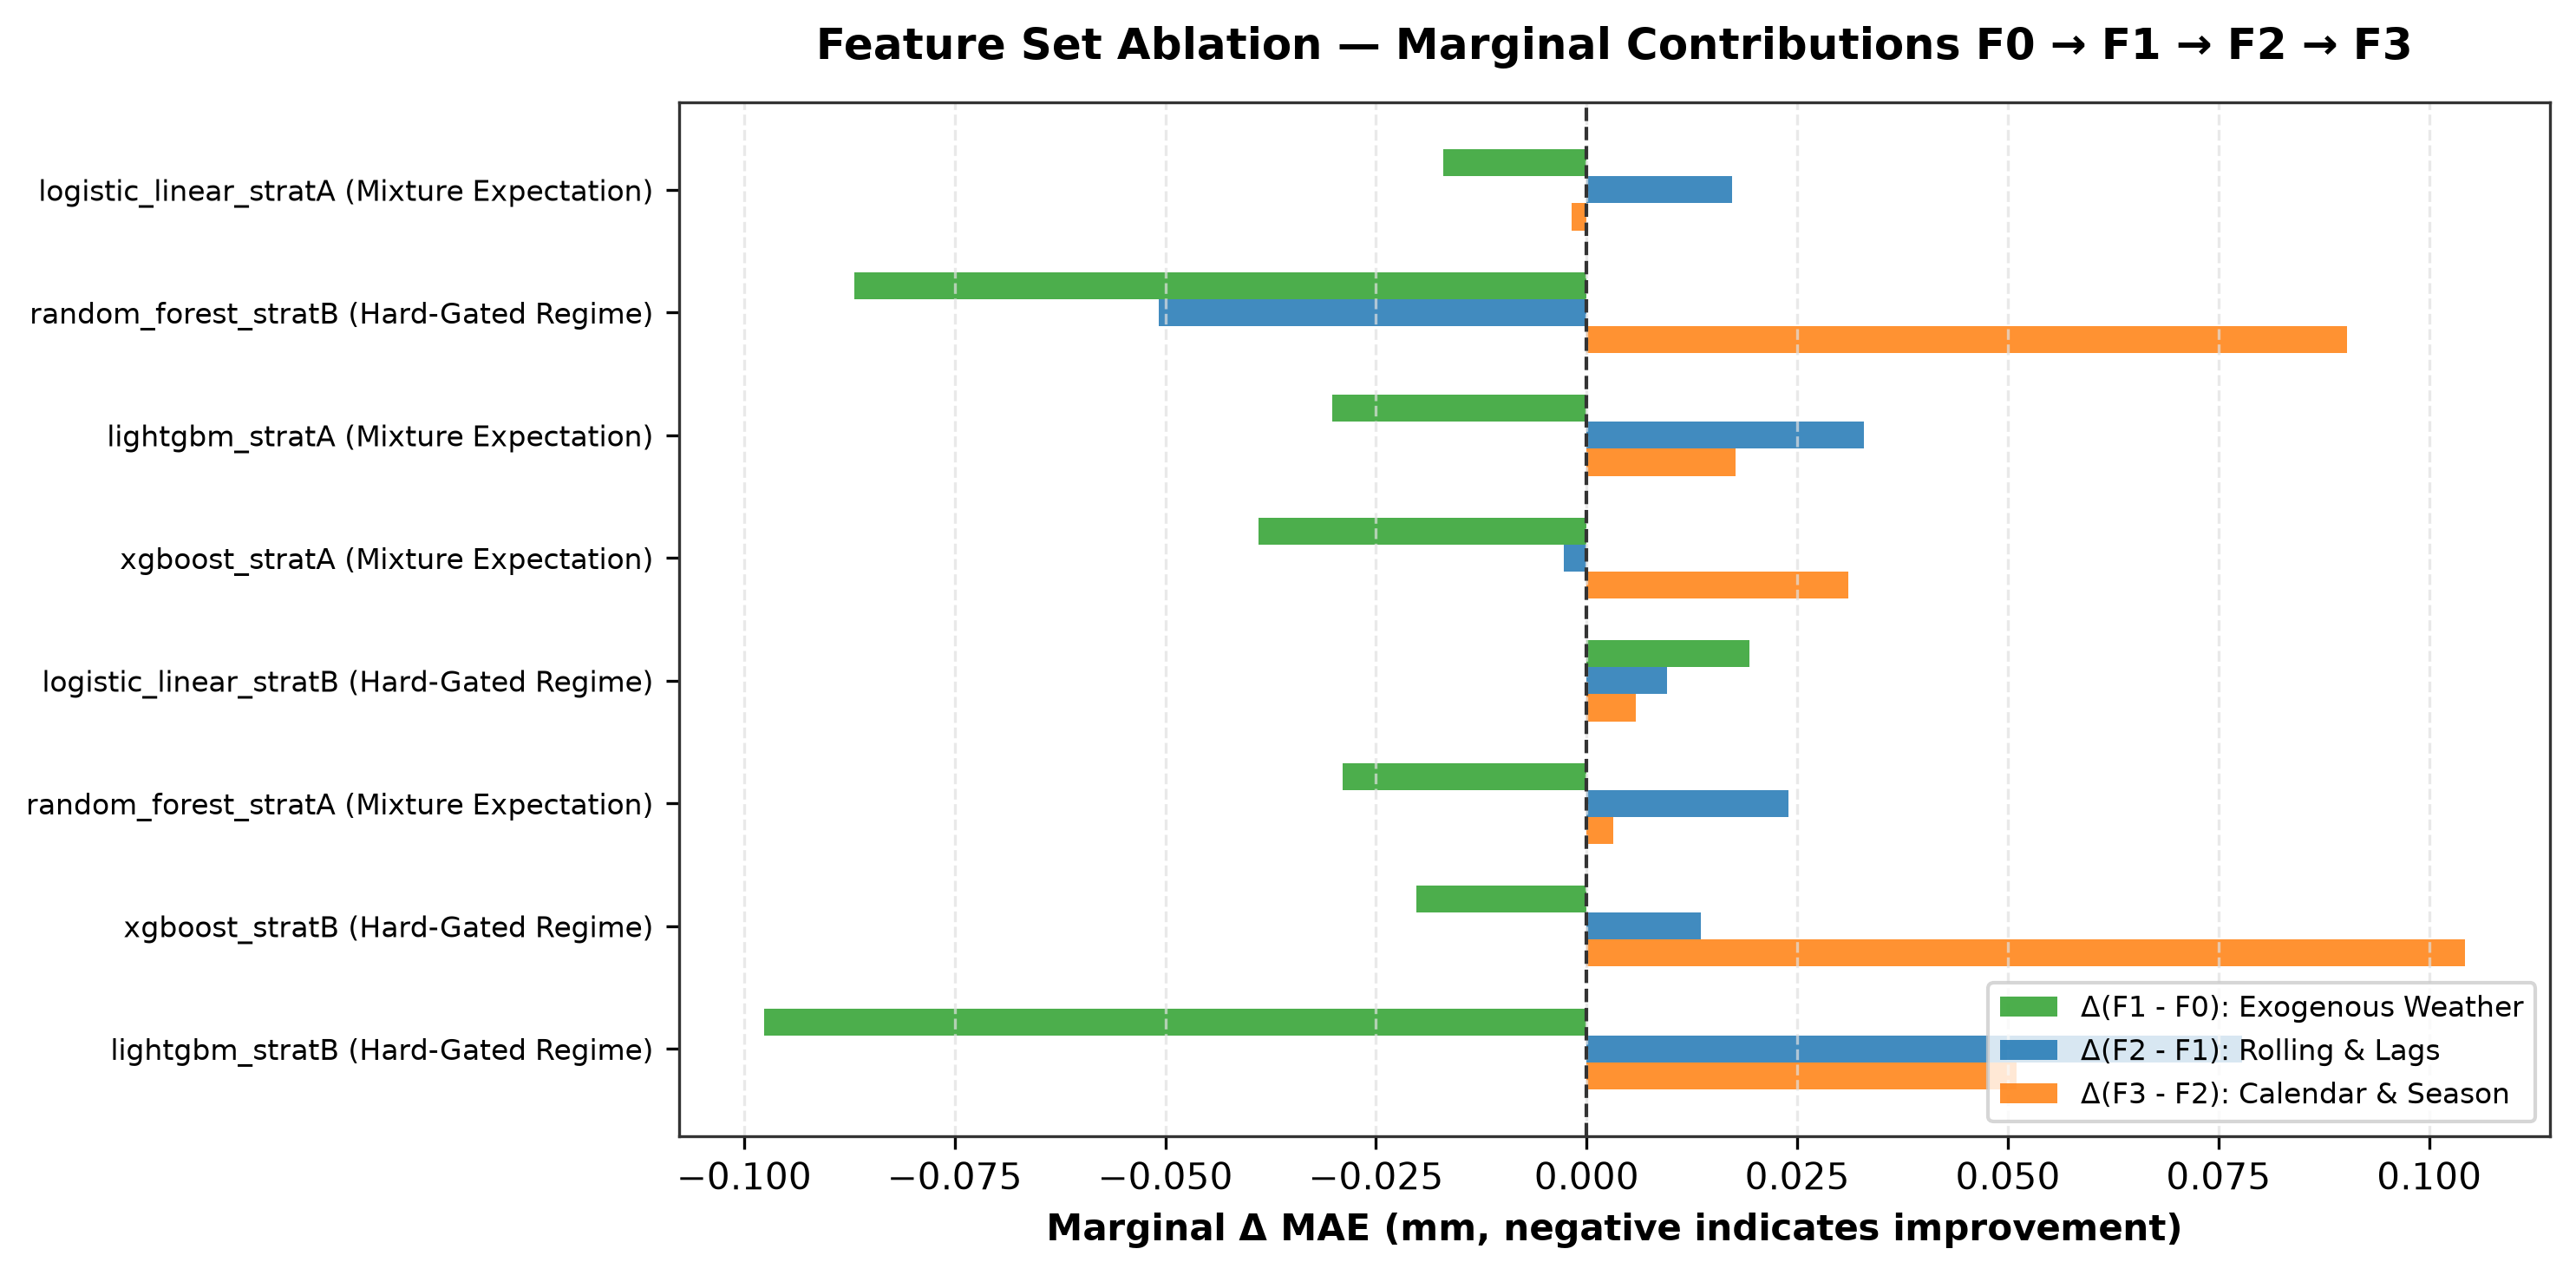

In [2]:
from src.analysis.loaders import load_all_validation_results
from src.analysis.aggregate import compute_feature_set_ablation
from src.analysis.plotting import plot_feature_ablation_matrix

df_results = load_all_validation_results()
df_ablation = compute_feature_set_ablation(df_results)
display(df_ablation)

fig = plot_feature_ablation_matrix(df_ablation, save_name="fig03_feature_ablation.png")
